In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

ModuleNotFoundError: No module named 'numpy'

In [2]:
import gc, pickle, glob
import h5py
import numpy as np

SUMMARY_KEYS = ['IR', 'QCharge', 'QDischarge', 'Tavg', 'Tmin', 'Tmax', 'chargetime', 'cycle']

def load_batch(mat_path, prefix, max_cycle=101):
    data = {}
    with h5py.File(mat_path, 'r') as f:
        batch = f['batch']
        n_cells = batch['summary'].shape[0]
        for i in range(n_cells):
            cycle_life = f[batch['cycle_life'][i, 0]][()]
            policy = f[batch['policy_readable'][i, 0]][()].tobytes()[::2].decode()
            s = f[batch['summary'][i, 0]]
            summary = {k: np.hstack(s[k][0, :].tolist()) for k in SUMMARY_KEYS}
            cycles = f[batch['cycles'][i, 0]]
            n_cyc = min(cycles['I'].shape[0], max_cycle)
            cyc = {}
            for j in range(n_cyc):
                cyc[str(j)] = {
                    'Qdlin': np.hstack(f[cycles['Qdlin'][j, 0]][()]),
                    'Tdlin': np.hstack(f[cycles['Tdlin'][j, 0]][()]),
                }
            data[f'{prefix}c{i}'] = {'cycle_life': cycle_life, 'charge_policy': policy,
                                     'summary': summary, 'cycles': cyc}
            print(f'{prefix}c{i} done ({i + 1}/{n_cells})')
    gc.collect()
    return data

def merge_batch1_batch2(b1, b2):
    b1_keys = ['b1c0', 'b1c1', 'b1c2', 'b1c3', 'b1c4']
    b2_keys = ['b2c7', 'b2c8', 'b2c9', 'b2c15', 'b2c16']
    add_len = [662, 981, 1060, 208, 482]
    for i, bk in enumerate(b1_keys):
        b1[bk]['cycle_life'] = b1[bk]['cycle_life'] + add_len[i]
        for k in b1[bk]['summary']:
            tail = b2[b2_keys[i]]['summary'][k]
            if k == 'cycle':
                tail = tail + len(b1[bk]['summary'][k])
            b1[bk]['summary'][k] = np.hstack((b1[bk]['summary'][k], tail))
    for k in b2_keys:
        del b2[k]
    for k in ['b1c8', 'b1c10', 'b1c12', 'b1c13', 'b1c22']:
        b1.pop(k, None)
    return b1, b2

In [3]:
import glob, pickle
def find(prefix):
    return glob.glob(f'/kaggle/input/**/{prefix}_batchdata*.mat', recursive=True)[0]
paths = {'b1': find('2017-05-12'), 'b2': find('2018-02-20'), 'b3': find('2018-04-12')}
print(paths)
batches = {p: load_batch(path, p) for p, path in paths.items()}
batches['b1'], batches['b2'] = merge_batch1_batch2(batches['b1'], batches['b2'])
for p, d in batches.items():
    with open(f'/kaggle/working/batch_{p}.pkl', 'wb') as fp:
        pickle.dump(d, fp)
    print(p, '셀 수:', len(d))

{'b1': '/kaggle/input/datasets/jooyoonpark/ess-analysis/2017-05-12_batchdata_updated_struct_errorcorrect.mat', 'b2': '/kaggle/input/datasets/jooyoonpark/ess-analysis/2018-02-20_batchdata_updated_struct_errorcorrect.mat', 'b3': '/kaggle/input/datasets/jooyoonpark/ess-analysis/2018-04-12_batchdata_updated_struct_errorcorrect.mat'}
b1c0 done (1/46)
b1c1 done (2/46)
b1c2 done (3/46)
b1c3 done (4/46)
b1c4 done (5/46)
b1c5 done (6/46)
b1c6 done (7/46)
b1c7 done (8/46)
b1c8 done (9/46)
b1c9 done (10/46)
b1c10 done (11/46)
b1c11 done (12/46)
b1c12 done (13/46)
b1c13 done (14/46)
b1c14 done (15/46)
b1c15 done (16/46)
b1c16 done (17/46)
b1c17 done (18/46)
b1c18 done (19/46)
b1c19 done (20/46)
b1c20 done (21/46)
b1c21 done (22/46)
b1c22 done (23/46)
b1c23 done (24/46)
b1c24 done (25/46)
b1c25 done (26/46)
b1c26 done (27/46)
b1c27 done (28/46)
b1c28 done (29/46)
b1c29 done (30/46)
b1c30 done (31/46)
b1c31 done (32/46)
b1c32 done (33/46)
b1c33 done (34/46)
b1c34 done (35/46)
b1c35 done (36/46)
b1c3

b1: 사용 셀 41개 | NaN 제거: []
b2: 사용 셀 34개 | NaN 제거: ['b2c22', 'b2c23', 'b2c35', 'b2c36', 'b2c37', 'b2c38', 'b2c39', 'b2c40']
b3: 사용 셀 44개 | NaN 제거: ['b3c23', 'b3c32']
b1 summary cycle 시작값: [1. 2. 3.]
b2 summary cycle 시작값: [1. 2. 3.]
b3 summary cycle 시작값: [1. 2. 3.]
batch
b1    41
b2    34
b3    44
dtype: int64


/tmp/ipykernel_58/1621345030.py:103: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  q1 = feat.groupby('batch').apply(q1_stats).round(2)


,n,mean,median,std,min,max,IQR,skew,long(>1000) %,short(<500) %
batch,,,,,,,,,,
b1,41.0,921.34,842.0,400.77,534.0,2237.0,264.00,2.06,24.39,0.00
b2,34.0,550.71,468.5,221.64,392.0,1186.0,59.25,1.88,8.82,76.47
b3,44.0,1059.66,1005.5,313.87,541.0,1935.0,327.25,1.21,52.27,0.00


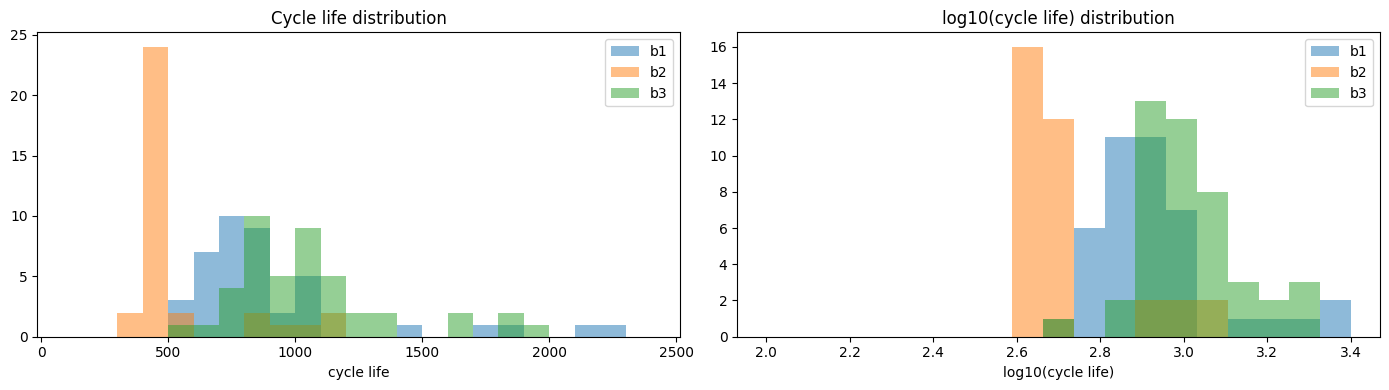

[b1] IQR 하한 306 미만 셀: []
[b2] IQR 하한 349 미만 셀: []
[b3] IQR 하한 337 미만 셀: []


,batch,cell,cycle_life,policy,C1,qd_2,ir_2,dq_logvar,ct_mean_2_6
55,b2,b2c19,392.0,6C(60%)-3C,6.0,1.091285,0.016773,-3.291958,10.175535
47,b2,b2c6,393.0,3.6C(9%)-5C,3.6,1.087554,0.016477,-3.530040,10.179131
57,b2,b2c21,408.0,6C(60%)-3C,6.0,1.098550,0.017284,-3.326679,10.174584
16,b1,b1c20,534.0,5.4C(80%)-5.4C,5.4,1.073182,0.015702,-3.367237,9.021115
102,b3,b3c28,541.0,3.7C(31%)-5.9C-newstructure,3.7,1.051867,0.013173,-3.451658,10.059142
17,b1,b1c21,559.0,5.4C(80%)-5.4C,5.4,1.083026,0.015311,-3.350338,8.964706
40,b1,b1c45,599.0,8C(35%)-3.6C,8.0,1.084608,0.016670,-3.425292,10.254465
81,b3,b3c6,667.0,3.7C(31%)-5.9C-newstructure,3.7,1.062612,0.013527,-3.525708,10.062472
105,b3,b3c31,731.0,5.9C(60%)-3.1C-newstructure,5.9,1.068181,0.015983,-3.839603,10.046478


,qd_2,ir_2,dq_logvar,C1,ct_mean_2_6
batch,,,,,
b1,1.0787,0.0167,-3.8383,6.0,10.9678
b2,1.0969,0.0169,-3.4840,5.2,10.1745
b3,1.0653,0.0155,-4.1752,5.3,10.0435


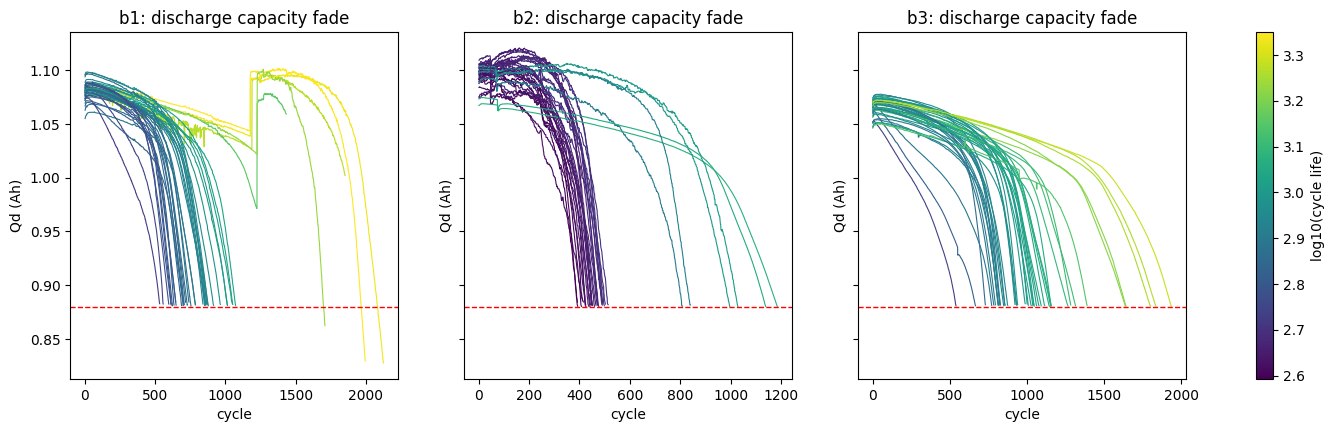

,early_slope(mAh/cyc),late_slope(mAh/cyc),acceleration(late/early),knee_cycle,knee/cycle_life
batch,,,,,
b1,-0.015,-0.951,44.608,593.0,0.715
b2,0.024,-1.523,-19.115,317.0,0.684
b3,-0.015,-0.911,47.481,764.5,0.758


,count,mean,std,min,25%,50%,75%,max
batch,,,,,,,,
b1,41.0,0.0018,0.0031,-0.0117,0.0013,0.0018,0.0039,0.0058
b2,34.0,0.0023,0.0067,-0.0202,-0.0008,0.0027,0.0071,0.0128
b3,44.0,0.0003,0.0048,-0.0187,0.0004,0.0015,0.0023,0.0038


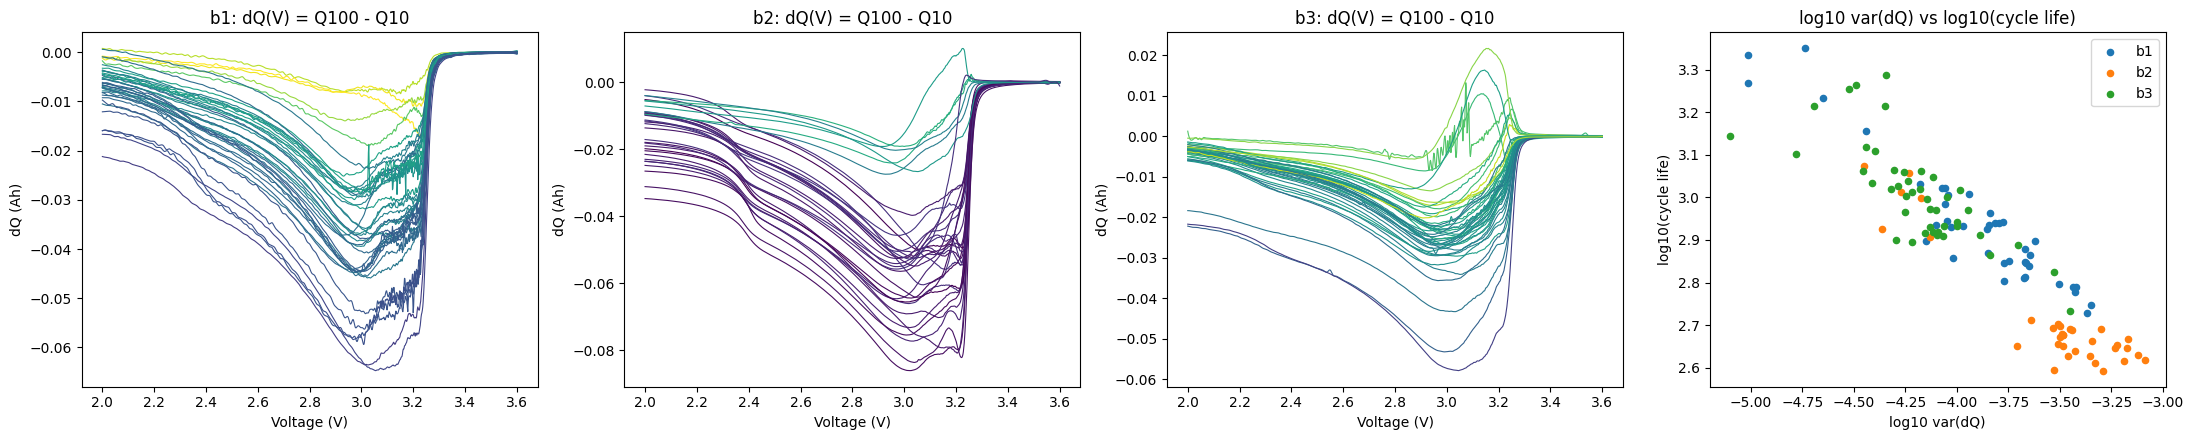

,logvar_long,logvar_short,diff(short-long),"r(dq_logvar, log_cl)","r(dq_logmin, log_cl)","r(dq_mean, log_cl)","r(dq_skew, log_cl)","r(dq_kurt, log_cl)"
batch,,,,,,,,
b1,-4.156,-3.653,0.503,-0.945,-0.916,0.846,-0.678,0.472
b2,-3.762,-3.330,0.432,-0.921,-0.906,0.769,-0.007,0.657
b3,-4.376,-4.012,0.365,-0.762,-0.744,0.720,0.188,0.341


,count,mean,std,min,25%,50%,75%,max
batch,,,,,,,,
b1,41.0,-3.910,0.399,-5.015,-4.055,-3.838,-3.667,-3.350
b2,34.0,-3.546,0.373,-4.449,-3.533,-3.484,-3.305,-3.086
b3,44.0,-4.194,0.292,-5.099,-4.323,-4.175,-4.066,-3.452


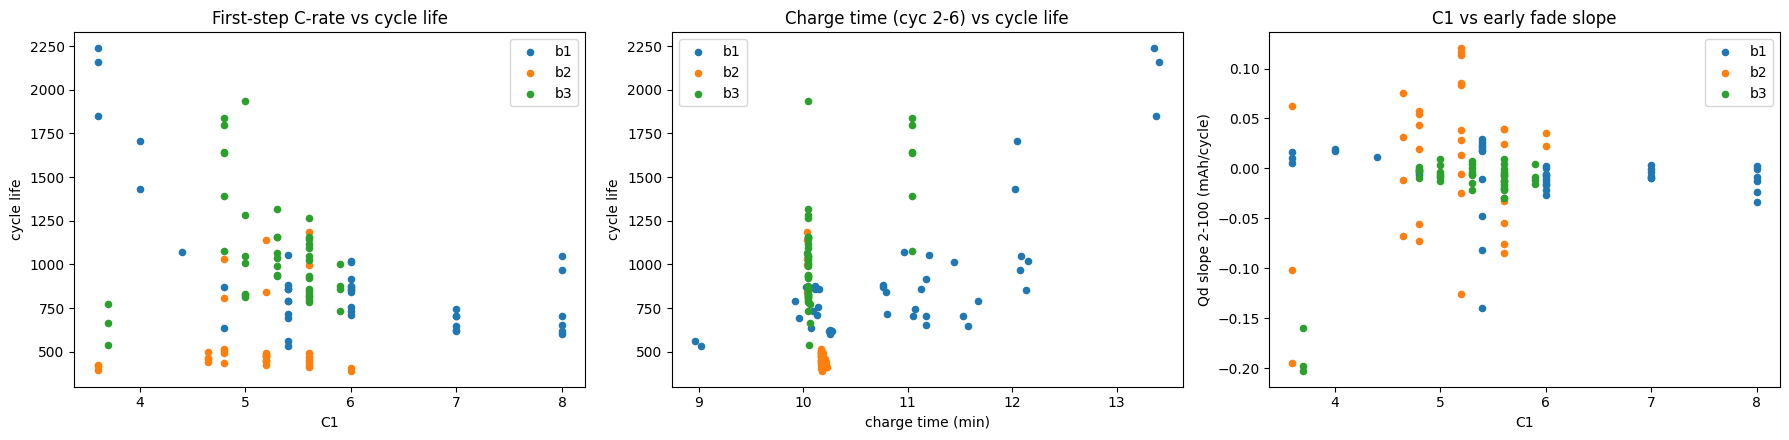

,n_policy,C1 range,fast mean CL,slow mean CL,fast vs slow (%),"r(C1, log_cl)","r(chargetime, log_cl)","r(C1, fade slope)",same-policy CV (%)
batch,,,,,,,,,
b1,22,3.6~8.0,785.70,1094.67,-28.23,-0.64,0.80,-0.18,7.32
b2,12,3.6~6.0,563.62,529.85,6.37,0.13,-0.94,0.24,7.67
b3,8,3.7~5.9,982.86,1194.06,-17.69,0.02,0.60,0.72,17.48


count    mean
batch policy                                    
b1    5.4C(80%)-5.4C                   2   546.0
      8C(35%)-3.6C                     2   608.0
      7C(40%)-3.6C                     2   621.0
      7C(40%)-3C                       2   676.0
      8C(25%)-3.6C                     2   676.0
      7C(30%)-3.6C                     2   722.0
      5.4C(70%)-3C                     2   740.0
      6C(60%)-3C                       2   744.0
      4.8C(80%)-4.8C                   2   753.0
      5.4C(50%)-3C                     1   788.0
      6C(50%)-3.6C                     2   792.0
      5.4C(60%)-3C                     2   800.0
      6C(40%)-3.6C                     2   856.0
      5.4C(60%)-3.6C                   2   860.0
      6C(50%)-3C                       2   888.0
      6C(40%)-3C                       2   936.0
      8C(15%)-3.6C                     2  1008.0
      6C(30%)-3.6C                     1  1014.0
      5.4C(40%)-3.6C                   1  1054.0
      4.4C(80%)-4.4C                   1  1074.0
      4C(80%)-4C                       2  1572.0
      3.6C(80%)-3.6C                   3  2083.0
b2    3.6C(9%)-5C                      1   393.0
      6C(60%)-3C                       2   400.0
      3.6C(30%)-6C                     2   421.0
      5.6C(26%)-4.5C                   6   448.0
      4.65C(69%)-6C                    2   452.0
      5.2C(50%)-4.25C                  5   454.0
      5.2C(58%)-4C                     4   478.0
      4.65C(44%)-5C                    2   482.0
      4.8C(80%)-4.8C                   4   486.0
      4.8C(80%)-4.8C-newstructure      2   919.0
      5.2C(58%)-4C-newstructure        2   990.0
      5.6C(26%)-4.5C-newstructure      2  1092.0
b3    3.7C(31%)-5.9C-newstructure      3   660.0
      5.9C(60%)-3.1C-newstructure      2   866.0
      5.9C(15%)-4.6C-newstructure      2   867.0
      5.6C(36%)-4.3C-newstructure      8   931.0
      5.6C(19%)-4.6C-newstructure      8  1001.0
      5.3C(54%)-4C-newstructure        8  1074.0
      5C(67%)-4C-newstructure          7  1106.0
      4.8C(80%)-4.8C-newstructure      6  1564.0

,b1,b2,b3,sign_consistent,min_|r|
dq_logvar,-0.945,-0.921,-0.762,True,0.762
dq_logmin,-0.916,-0.906,-0.744,True,0.744
dq_mean,0.846,0.769,0.720,True,0.720
ct_mean_2_6,0.800,-0.945,0.601,False,0.601
qd_slope_2_100,0.491,-0.418,0.433,False,0.418
dq_kurt,0.472,0.657,0.341,True,0.341
qd_100_minus_2,0.526,-0.233,0.376,False,0.233
ir_min_2_100,0.343,-0.572,0.172,False,0.172
qd_max_minus_2,0.570,-0.379,0.125,False,0.125
ir_100_minus_2,0.112,0.245,-0.467,False,0.112


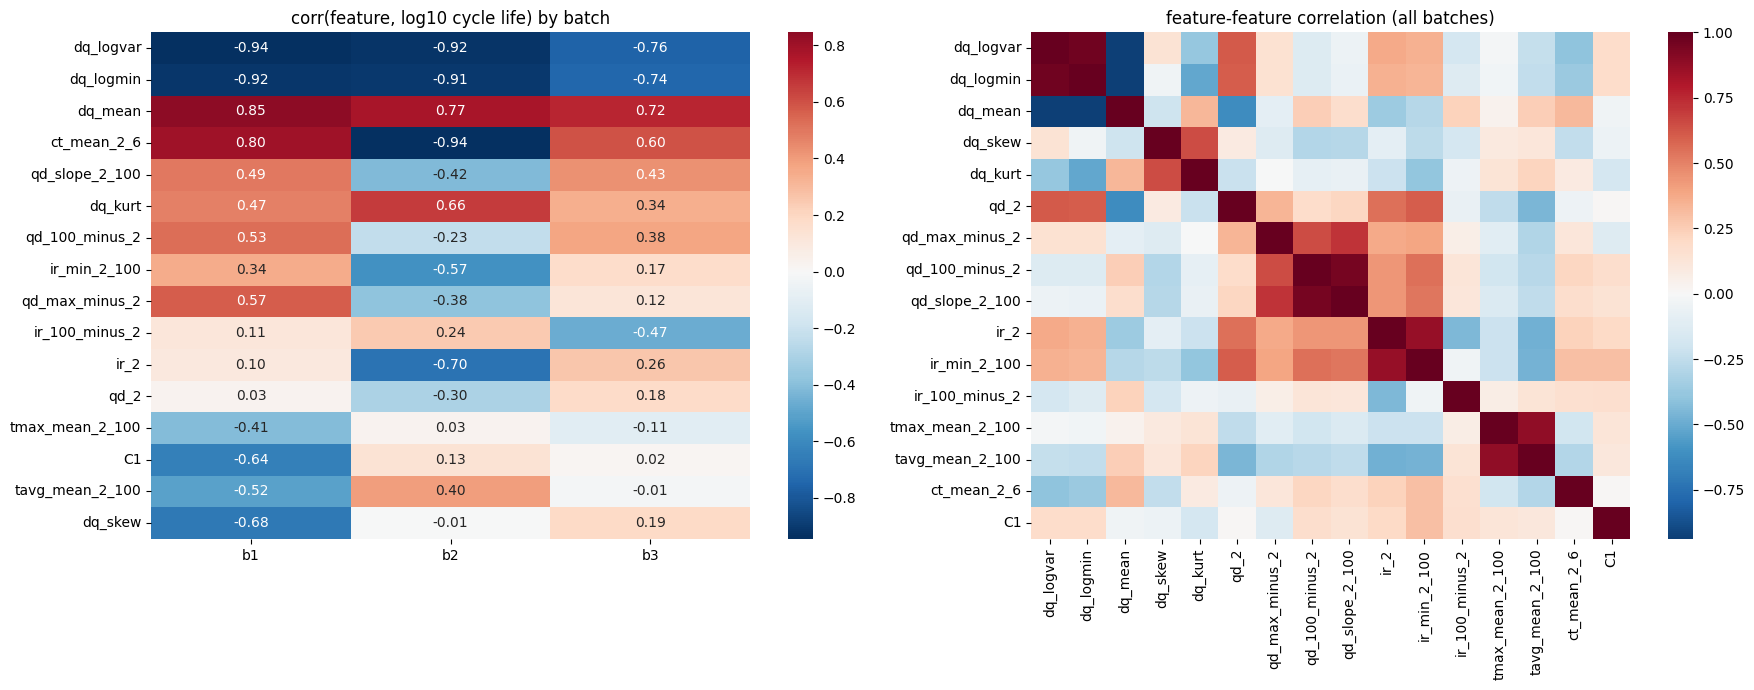

,VIF (b1)
dq_logvar,468.5
dq_logmin,415.6
ir_2,213.7
qd_100_minus_2,183.9
ir_100_minus_2,183.4
qd_slope_2_100,163.9
ir_min_2_100,90.6
tavg_mean_2_100,42.0
tmax_mean_2_100,33.3
dq_mean,29.4


In [5]:
# ============================================================
# ESS 배터리 수명 EDA (Q1~Q5) - "# %%" 단위로 노트북 셀 하나씩 붙여넣기
# 그래프 라벨은 영어 (Kaggle 기본 폰트에 한글이 없어 깨짐)
# ============================================================

# %% [Cell A] pkl 로드 + 기본 정리
import pickle, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew, kurtosis

BATCHES = ['b1', 'b2', 'b3']
COLORS = {'b1': 'tab:blue', 'b2': 'tab:orange', 'b3': 'tab:green'}

data = {}
for b in BATCHES:
    with open(f'/kaggle/working/batch_{b}.pkl', 'rb') as fp:
        data[b] = pickle.load(fp)

def to_float(x):
    return float(np.ravel(x)[0])

# cycle_life가 NaN(EOL 미도달)인 셀 제거
for b in BATCHES:
    drop = [k for k, v in data[b].items() if not np.isfinite(to_float(v['cycle_life']))]
    for k in drop:
        del data[b][k]
    print(f'{b}: 사용 셀 {len(data[b])}개 | NaN 제거: {drop}')

# 사이클 번호 확인: summary['cycle']이 1부터 시작하면 cycles key '99' = 100번째 사이클
for b in BATCHES:
    first = next(iter(data[b].values()))
    print(b, 'summary cycle 시작값:', first['summary']['cycle'][:3])

def cyc_key(cell, n):
    """사이클 번호 n -> cycles 딕셔너리 key"""
    offset = int(cell['summary']['cycle'][0])
    return str(n - offset)


# %% [Cell B] 셀 단위 피처 테이블 생성 (Q1~Q5 공통 사용)
V = np.linspace(3.6, 2.0, 1000)  # Qdlin 전압 축

def series(cell, key, lo=None, hi=None):
    sm = cell['summary']
    s = pd.Series(sm[key], index=sm['cycle'].astype(int))
    if lo is not None:
        s = s[(s > lo) & (s < hi)]
    return s

def delta_q(cell, hi=100, lo=10):
    return cell['cycles'][cyc_key(cell, hi)]['Qdlin'] - cell['cycles'][cyc_key(cell, lo)]['Qdlin']

def first_crate(policy):
    m = re.findall(r'([\d.]+)C', policy)
    return float(m[0]) if m else np.nan

rows = []
for b in BATCHES:
    for cid, cell in data[b].items():
        cl = to_float(cell['cycle_life'])
        qd = series(cell, 'QDischarge', 0.8, 1.2)       # 이상치(0, 스파이크) 제거
        ir = series(cell, 'IR', 0, 1)
        ct = series(cell, 'chargetime', 0, 60)
        tmax = series(cell, 'Tmax', 0, 80)
        tavg = series(cell, 'Tavg', 0, 80)
        q_early = qd.loc[2:100]
        d = delta_q(cell)
        rows.append({
            'batch': b, 'cell': cid, 'policy': cell['charge_policy'],
            'C1': first_crate(cell['charge_policy']),
            'cycle_life': cl, 'log_cl': np.log10(cl),
            # ΔQ(V) 피처 (Q3)
            'dq_logvar': np.log10(np.var(d)), 'dq_logmin': np.log10(np.abs(d.min()) + 1e-12),
            'dq_mean': d.mean(), 'dq_skew': skew(d), 'dq_kurt': kurtosis(d),
            # 방전 용량 피처 (Q2)
            'qd_2': qd.loc[1:3].median(),
            'qd_max_minus_2': q_early.max() - qd.loc[1:3].median(),
            'qd_100_minus_2': qd.loc[98:100].median() - qd.loc[1:3].median(),
            'qd_slope_2_100': np.polyfit(q_early.index, q_early.values, 1)[0] * 1000,  # mAh/cycle
            # 저항, 온도, 충전 시간
            'ir_2': ir.loc[1:3].median(), 'ir_min_2_100': ir.loc[2:100].min(),
            'ir_100_minus_2': ir.loc[98:100].median() - ir.loc[1:3].median(),
            'tmax_mean_2_100': tmax.loc[2:100].mean(), 'tavg_mean_2_100': tavg.loc[2:100].mean(),
            'ct_mean_2_6': ct.loc[2:6].mean(),
        })
feat = pd.DataFrame(rows)
print(feat.groupby('batch').size())
feat.head()


# %% [Cell C] Q1. Cycle Life 분포 + 배치 비교표 + 이상치
def q1_stats(g):
    cl = g['cycle_life']
    return pd.Series({
        'n': len(cl), 'mean': cl.mean(), 'median': cl.median(), 'std': cl.std(),
        'min': cl.min(), 'max': cl.max(), 'IQR': cl.quantile(.75) - cl.quantile(.25),
        'skew': skew(cl), 'long(>1000) %': (cl > 1000).mean() * 100,
        'short(<500) %': (cl < 500).mean() * 100,
    })
q1 = feat.groupby('batch').apply(q1_stats).round(2)
display(q1)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for b in BATCHES:
    g = feat[feat.batch == b]
    ax[0].hist(g.cycle_life, bins=np.linspace(100, 2400, 24), alpha=.5, label=b, color=COLORS[b])
    ax[1].hist(g.log_cl, bins=np.linspace(2, 3.4, 20), alpha=.5, label=b, color=COLORS[b])
ax[0].set(title='Cycle life distribution', xlabel='cycle life'); ax[0].legend()
ax[1].set(title='log10(cycle life) distribution', xlabel='log10(cycle life)'); ax[1].legend()
plt.tight_layout(); plt.show()

# 이상치: 배치 내 IQR 하한 미만 + 배치별 최단 수명 3개 (원인 파악용 피처 같이 출력)
cols = ['batch', 'cell', 'cycle_life', 'policy', 'C1', 'qd_2', 'ir_2', 'dq_logvar', 'ct_mean_2_6']
for b in BATCHES:
    g = feat[feat.batch == b]
    fence = g.cycle_life.quantile(.25) - 1.5 * (g.cycle_life.quantile(.75) - g.cycle_life.quantile(.25))
    print(f'[{b}] IQR 하한 {fence:.0f} 미만 셀:', g[g.cycle_life < fence].cell.tolist())
display(feat.sort_values('cycle_life').groupby('batch').head(3)[cols])
# 비교용: 배치별 피처 중앙값 -> 단수명 셀이 어떤 값에서 튀는지 비교
display(feat.groupby('batch')[['qd_2', 'ir_2', 'dq_logvar', 'C1', 'ct_mean_2_6']].median().round(4))


# %% [Cell D] Q2. 열화 곡선 + 열화 가속 + Knee point
# 주의: knee / late slope는 EOL까지의 전체 데이터를 쓰므로 "EDA 전용" (모델 피처로 쓰면 누수)
def knee_point(s):
    x = s.index.values.astype(float); y = s.values
    xn = (x - x.min()) / (x.max() - x.min()); yn = (y - y.min()) / (y.max() - y.min() + 1e-12)
    dist = np.abs((yn[-1] - yn[0]) * xn - (xn[-1] - xn[0]) * yn + xn[-1] * yn[0] - yn[-1] * xn[0])
    return x[np.argmax(dist)]

norm = plt.Normalize(feat.log_cl.min(), feat.log_cl.max())
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)
q2_rows = []
for ax, b in zip(axes, BATCHES):
    for cid, cell in data[b].items():
        cl = to_float(cell['cycle_life'])
        qd = series(cell, 'QDischarge', 0.8, 1.2)
        qd = qd[qd.index <= cl].rolling(5, center=True, min_periods=1).median()
        ax.plot(qd.index, qd.values, color=plt.cm.viridis(norm(np.log10(cl))), lw=.8)
        early, late = qd.loc[10:100], qd.loc[max(cl - 100, 101):cl]
        k = knee_point(qd.loc[2:])
        q2_rows.append({'batch': b, 'cell': cid, 'cycle_life': cl,
                        'early_slope(mAh/cyc)': np.polyfit(early.index, early.values, 1)[0] * 1000,
                        'late_slope(mAh/cyc)': np.polyfit(late.index, late.values, 1)[0] * 1000 if len(late) > 10 else np.nan,
                        'knee_cycle': k, 'knee/cycle_life': k / cl})
    ax.axhline(0.88, ls='--', c='r', lw=1)  # EOL = 80% of 1.1Ah
    ax.set(title=f'{b}: discharge capacity fade', xlabel='cycle', ylabel='Qd (Ah)')
fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap='viridis'), ax=axes, label='log10(cycle life)')
plt.show()

q2 = pd.DataFrame(q2_rows)
q2['acceleration(late/early)'] = q2['late_slope(mAh/cyc)'] / q2['early_slope(mAh/cyc)']
display(q2.groupby('batch')[['early_slope(mAh/cyc)', 'late_slope(mAh/cyc)',
                             'acceleration(late/early)', 'knee_cycle', 'knee/cycle_life']].median().round(3))
# 초기 100 사이클 동안 용량이 거의 안 줄었는지 (= 용량 감소만으로는 조기 예측 어려움)
display(feat.groupby('batch')['qd_100_minus_2'].describe().round(4))


# %% [Cell E] Q3. ΔQ(V) = Q100 - Q10 곡선 + 장/단수명 비교
fig, axes = plt.subplots(1, 4, figsize=(22, 4.5))
for ax, b in zip(axes[:3], BATCHES):
    for cid, cell in data[b].items():
        cl = to_float(cell['cycle_life'])
        ax.plot(V, delta_q(cell), color=plt.cm.viridis(norm(np.log10(cl))), lw=.8)
    ax.set(title=f'{b}: dQ(V) = Q100 - Q10', xlabel='Voltage (V)', ylabel='dQ (Ah)')
for b in BATCHES:
    g = feat[feat.batch == b]
    axes[3].scatter(g.dq_logvar, g.log_cl, label=b, color=COLORS[b], s=20)
axes[3].set(title='log10 var(dQ) vs log10(cycle life)', xlabel='log10 var(dQ)', ylabel='log10(cycle life)')
axes[3].legend(); plt.tight_layout(); plt.show()

# 배치 내 중앙값 기준 장/단수명 그룹 비교 + 상관계수
q3_rows = []
for b in BATCHES:
    g = feat[feat.batch == b]
    long_ = g[g.cycle_life >= g.cycle_life.median()]; short_ = g[g.cycle_life < g.cycle_life.median()]
    q3_rows.append({'batch': b,
                    'logvar_long': long_.dq_logvar.mean(), 'logvar_short': short_.dq_logvar.mean(),
                    'diff(short-long)': short_.dq_logvar.mean() - long_.dq_logvar.mean(),
                    **{f'r({c}, log_cl)': g[c].corr(g.log_cl) for c in
                       ['dq_logvar', 'dq_logmin', 'dq_mean', 'dq_skew', 'dq_kurt']}})
display(pd.DataFrame(q3_rows).set_index('batch').round(3))
# 배치 간 dq_logvar 범위 차이 (스케일 이동 여부 확인)
display(feat.groupby('batch')['dq_logvar'].describe().round(3))


# %% [Cell F] Q4. 충전 조건(C-rate)과 수명
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
for b in BATCHES:
    g = feat[feat.batch == b]
    ax[0].scatter(g.C1, g.cycle_life, label=b, color=COLORS[b], s=20)
    ax[1].scatter(g.ct_mean_2_6, g.cycle_life, label=b, color=COLORS[b], s=20)
    ax[2].scatter(g.C1, g.qd_slope_2_100, label=b, color=COLORS[b], s=20)
ax[0].set(title='First-step C-rate vs cycle life', xlabel='C1', ylabel='cycle life')
ax[1].set(title='Charge time (cyc 2-6) vs cycle life', xlabel='charge time (min)', ylabel='cycle life')
ax[2].set(title='C1 vs early fade slope', xlabel='C1', ylabel='Qd slope 2-100 (mAh/cycle)')
for a in ax: a.legend()
plt.tight_layout(); plt.show()

q4_rows = []
for b in BATCHES:
    g = feat[feat.batch == b]
    fast = g[g.C1 >= g.C1.median()]; slow = g[g.C1 < g.C1.median()]
    rep = g.groupby('policy').cycle_life.agg(['count', 'mean', 'std']).query('count >= 2')
    q4_rows.append({'batch': b, 'n_policy': g.policy.nunique(),
                    'C1 range': f'{g.C1.min():.1f}~{g.C1.max():.1f}',
                    'fast mean CL': fast.cycle_life.mean(), 'slow mean CL': slow.cycle_life.mean(),
                    'fast vs slow (%)': (fast.cycle_life.mean() / slow.cycle_life.mean() - 1) * 100,
                    'r(C1, log_cl)': g.C1.corr(g.log_cl),
                    'r(chargetime, log_cl)': g.ct_mean_2_6.corr(g.log_cl),
                    'r(C1, fade slope)': g.C1.corr(g.qd_slope_2_100),
                    'same-policy CV (%)': (rep['std'] / rep['mean']).mean() * 100 if len(rep) else np.nan})
display(pd.DataFrame(q4_rows).set_index('batch').round(2))
# 프로토콜별 평균 수명 (배치별 상/하위)
display(feat.groupby(['batch', 'policy']).cycle_life.agg(['count', 'mean']).round(0)
        .sort_values(['batch', 'mean']))


# %% [Cell G] Q5. 상관관계 (배치별 일관성) + 다중공선성
from statsmodels.stats.outliers_influence import variance_inflation_factor
FEATS = ['dq_logvar', 'dq_logmin', 'dq_mean', 'dq_skew', 'dq_kurt', 'qd_2', 'qd_max_minus_2',
         'qd_100_minus_2', 'qd_slope_2_100', 'ir_2', 'ir_min_2_100', 'ir_100_minus_2',
         'tmax_mean_2_100', 'tavg_mean_2_100', 'ct_mean_2_6', 'C1']

corr_tbl = pd.DataFrame({b: feat[feat.batch == b][FEATS].corrwith(feat[feat.batch == b].log_cl)
                         for b in BATCHES})
corr_tbl['sign_consistent'] = np.sign(corr_tbl[BATCHES]).nunique(axis=1) == 1
corr_tbl['min_|r|'] = corr_tbl[BATCHES].abs().min(axis=1)
corr_tbl = corr_tbl.sort_values('min_|r|', ascending=False)
display(corr_tbl.round(3))

fig, ax = plt.subplots(1, 2, figsize=(18, 7))
sns.heatmap(corr_tbl[BATCHES], annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=ax[0])
ax[0].set_title('corr(feature, log10 cycle life) by batch')
sns.heatmap(feat[FEATS].corr(), cmap='RdBu_r', center=0, ax=ax[1])
ax[1].set_title('feature-feature correlation (all batches)')
plt.tight_layout(); plt.show()

# VIF (Batch 1 = 학습 배치 기준, 10 이상이면 다중공선성 의심)
X = feat[feat.batch == 'b1'][FEATS].dropna()
X = (X - X.mean()) / X.std()
vif = pd.Series([variance_inflation_factor(X.values, i) for i in range(X.shape[1])], index=FEATS)
display(vif.sort_values(ascending=False).round(1).to_frame('VIF (b1)'))


In [6]:
!ls -la /kaggle/working

total 211076
drwxr-xr-x 3 root root     4096 Oct  2 00:18 .
drwxr-xr-x 5 root root     4096 Oct  2 00:17 ..
-rw-r--r-- 1 root root 68380889 Oct  2 00:18 batch_b1.pkl
-rw-r--r-- 1 root root 69738724 Oct  2 00:18 batch_b2.pkl
-rw-r--r-- 1 root root 78004010 Oct  2 00:18 batch_b3.pkl
drwxr-xr-x 2 root root     4096 Oct  2 00:17 .virtual_documents


In [8]:
"""
모델 학습 및 평가 (DAY 1 모델 설계 전략 구현)

[분할]
- Batch 1을 충전 프로토콜 단위로 나눔 (GroupShuffleSplit, 20%) → Train / Valid(Hold-out)
- Train 안에서 프로토콜 그룹 기준 GroupKFold(5)로 하이퍼파라미터 탐색 → Train(CV) 성능
- 선택된 하이퍼파라미터로 Batch 1 전체 재학습 → Test(Batch 2), 추가 Test(Batch 3)

[Target / Metric]
- Target: log10(cycle_life), MAPE는 원 단위(cycle)로 역변환해서 계산
- Gap은 "후단계 오차 - 전단계 오차" (MAPE는 낮을수록 좋으므로 (+) = 성능 저하)

사용법:
    python src/train.py --features data/processed/features.csv --out_dir results
노트북:
    이 파일 내용을 셀에 붙여넣고  out = run_all(feat, out_dir='/kaggle/working/results')
"""
import argparse
import json
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import ElasticNet, Lasso, LinearRegression, Ridge
from sklearn.metrics import make_scorer
from sklearn.model_selection import GridSearchCV, GroupKFold, GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42
PAPER_MAPE = 9.1                 # 원논문 Regression 테스트 오차 (%)
MAIN_MODEL = 'ElasticNet'
FEATURES_VARIANCE = ['dq_logvar']                                   # 베이스라인 (원논문 variance model 형태)
FEATURES_MAIN = ['dq_logvar', 'dq_logmin', 'dq_mean', 'dq_kurt',    # DAY 1 Feature Engineering 결과
                 'qd_2', 'qd_max_minus_2']


# ------------------------------------------------------------------ metric
def mape_log(y_true_log, y_pred_log):
    """log10 스케일 값을 받아 원 단위(cycle)로 되돌린 뒤 MAPE(%) 계산"""
    t = 10 ** np.asarray(y_true_log, dtype=float)
    p = 10 ** np.asarray(y_pred_log, dtype=float)
    return float(np.mean(np.abs(p - t) / t) * 100)


MAPE_SCORER = make_scorer(mape_log, greater_is_better=False)
_LGBM_WARNED = False


# ------------------------------------------------------------------ models
def get_models():
    """{이름: (estimator, param_grid, 사용 피처)}"""
    alphas = np.logspace(-4, 0, 9)
    models = {
        'Linear (dq_logvar)': (make_pipeline(StandardScaler(), LinearRegression()),
                               {}, FEATURES_VARIANCE),
        'Ridge': (make_pipeline(StandardScaler(), Ridge()),
                  {'ridge__alpha': np.logspace(-3, 2, 11)}, FEATURES_MAIN),
        'Lasso': (make_pipeline(StandardScaler(), Lasso(max_iter=50000)),
                  {'lasso__alpha': alphas}, FEATURES_MAIN),
        'ElasticNet': (make_pipeline(StandardScaler(), ElasticNet(max_iter=50000)),
                       {'elasticnet__alpha': alphas,
                        'elasticnet__l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9]}, FEATURES_MAIN),
        'RandomForest': (RandomForestRegressor(n_estimators=500, min_samples_leaf=2, random_state=SEED),
                         {'max_depth': [2, 3, None]}, FEATURES_MAIN),
    }
    try:
        from lightgbm import LGBMRegressor
        models['LightGBM'] = (LGBMRegressor(n_estimators=300, learning_rate=0.05, num_leaves=7,
                                            min_child_samples=3, random_state=SEED, verbose=-1),
                              {'max_depth': [2, 3]}, FEATURES_MAIN)
    except ImportError:
        global _LGBM_WARNED
        if not _LGBM_WARNED:
            print('[info] lightgbm 미설치 → LightGBM 비교 생략')
            _LGBM_WARNED = True
    return models


# ------------------------------------------------------------------ split
def split_batch1(feat, test_size=0.2, seed=SEED):
    """Batch 1을 충전 프로토콜 단위로 Train / Hold-out 분리 (같은 프로토콜 셀이 양쪽에 섞이지 않음)"""
    b1 = feat[feat.batch == 'b1'].reset_index(drop=True)
    gss = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=seed)
    tr_idx, ho_idx = next(gss.split(b1, groups=b1['policy']))
    return b1, b1.iloc[tr_idx].reset_index(drop=True), b1.iloc[ho_idx].reset_index(drop=True)


def _clean_params(params):
    return {k: (v.item() if hasattr(v, 'item') else v) for k, v in params.items()}


# ------------------------------------------------------------------ evaluate
def evaluate_model(name, estimator, grid, cols, b1, train, holdout, tests, n_splits=5):
    gs = GridSearchCV(estimator, grid, scoring=MAPE_SCORER, cv=GroupKFold(n_splits=n_splits), refit=True)
    gs.fit(train[cols], train['log_cl'], groups=train['policy'])

    res = {'model': name, 'features': ', '.join(cols),
           'best_params': json.dumps(_clean_params(gs.best_params_)),
           'Train (Batch 1 CV)': -gs.best_score_,
           'Train fit (참고)': mape_log(train['log_cl'], gs.predict(train[cols])),
           'Valid (Batch 1 Hold-out)': mape_log(holdout['log_cl'], gs.predict(holdout[cols]))}

    final = clone(gs.best_estimator_).fit(b1[cols], b1['log_cl'])   # Batch 1 전체로 재학습
    preds = {}
    for tname, tdf in tests.items():
        p = final.predict(tdf[cols])
        res[f'Test ({tname})'] = mape_log(tdf['log_cl'], p)
        preds[tname] = p
    return res, final, preds


def add_gaps(df):
    df['Gap (Train-Valid)'] = df['Valid (Batch 1 Hold-out)'] - df['Train (Batch 1 CV)']
    df['Gap (Valid-Test)'] = df['Test (Batch 2)'] - df['Valid (Batch 1 Hold-out)']
    df['Gap (Target-Test)'] = df['Test (Batch 2)'] - PAPER_MAPE
    df['Gap (Batch2-Batch3)'] = df['Test (Batch 3)'] - df['Test (Batch 2)']
    df['Gap (Target-Test, Batch 3)'] = df['Test (Batch 3)'] - PAPER_MAPE
    return df


def performance_table(row):
    """과제 Reporting format (Batch 3 추가 포함) 형태의 표"""
    r = lambda k: round(float(row[k]), 2)
    return pd.DataFrame([
        ['Train (Batch 1 CV)', r('Train (Batch 1 CV)'), '프로토콜 그룹 GroupKFold(5) 평균'],
        ['Valid (Batch 1 Hold-out)', r('Valid (Batch 1 Hold-out)'), '프로토콜 단위 20% 분리'],
        ['Test (Batch 2)', r('Test (Batch 2)'), 'Batch 1 전체 재학습 후 평가'],
        ['Gap (Train-Valid)', r('Gap (Train-Valid)'), '(+) : 과적합 의심'],
        ['Gap (Valid-Test)', r('Gap (Valid-Test)'), '(+) : 배치간 일반화 저하 의심'],
        ['Gap (Target-Test)', r('Gap (Target-Test)'), f'Target : 원논문 {PAPER_MAPE}% / (+) : 논문 대비 미달'],
        ['Test (Batch 3)', r('Test (Batch 3)'), ''],
        ['Gap (Batch2-Batch3)', r('Gap (Batch2-Batch3)'), 'Test 성능 간 비교'],
        ['Gap (Target-Test, Batch 3)', r('Gap (Target-Test, Batch 3)'), 'Batch 3 기준, 원논문 성능 비교'],
    ], columns=['구분', 'MAPE (%)', '비고'])


# ------------------------------------------------------------------ error analysis
def build_predictions(final, cols, b1, tests, preds):
    frames = [b1.assign(pred_log=final.predict(b1[cols]), split='Batch 1 (fit)')]
    for tname, tdf in tests.items():
        frames.append(tdf.assign(pred_log=preds[tname], split=tname))
    df = pd.concat(frames, ignore_index=True)
    df['pred_cycle_life'] = 10 ** df['pred_log']
    df['error(%)'] = (df['pred_cycle_life'] - df['cycle_life']) / df['cycle_life'] * 100  # (+) 과대 예측
    df['APE(%)'] = df['error(%)'].abs()
    lo, hi = b1['cycle_life'].min(), b1['cycle_life'].max()
    flo, fhi = b1['dq_logvar'].min(), b1['dq_logvar'].max()
    df['target_out_of_b1_range'] = (df['cycle_life'] < lo) | (df['cycle_life'] > hi)
    df['dq_logvar_out_of_b1_range'] = (df['dq_logvar'] < flo) | (df['dq_logvar'] > fhi)
    return df


def error_analysis(pred_df, top_n=5):
    test = pred_df[pred_df.split != 'Batch 1 (fit)']
    cols = ['split', 'cell', 'policy', 'cycle_life', 'pred_cycle_life', 'error(%)', 'dq_logvar',
            'target_out_of_b1_range', 'dq_logvar_out_of_b1_range']
    top = test.sort_values('APE(%)', ascending=False).groupby('split').head(top_n)[cols]
    by_range = test.groupby(['split', 'target_out_of_b1_range'])['APE(%)'].agg(['count', 'mean']).round(2)
    bias = test.groupby('split')['error(%)'].agg(['mean', 'median']).round(2)   # (+) 과대 / (-) 과소
    by_policy = (test.groupby(['split', 'policy'])['APE(%)'].agg(['count', 'mean'])
                 .sort_values('mean', ascending=False).round(2))
    return {'top_errors': top, 'by_range': by_range, 'bias': bias, 'by_policy': by_policy}


# ------------------------------------------------------------------ plots
def plot_pred_vs_actual(pred_df, path, title):
    colors = {'Batch 1 (fit)': 'tab:blue', 'Batch 2': 'tab:orange', 'Batch 3': 'tab:green'}
    fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
    for s, g in pred_df.groupby('split'):
        ax[0].scatter(g.cycle_life, g.pred_cycle_life, s=22, label=s, color=colors.get(s))
        ax[1].scatter(g.cycle_life, g['error(%)'], s=22, label=s, color=colors.get(s))
    lim = [300, 2500]
    ax[0].plot(lim, lim, 'k--', lw=1)
    ax[0].fill_between(lim, [v * 0.85 for v in lim], [v * 1.15 for v in lim], color='gray', alpha=.15,
                       label='±15%')
    ax[0].set(xscale='log', yscale='log', xlim=lim, ylim=lim, xlabel='actual cycle life',
              ylabel='predicted cycle life', title=f'{title}: predicted vs actual')
    ax[1].axhline(0, c='k', lw=1)
    ax[1].set(xscale='log', xlabel='actual cycle life', ylabel='error (%) [+ over / - under]',
              title=f'{title}: error vs actual life')
    for a in ax:
        a.legend()
    plt.tight_layout()
    plt.savefig(path, dpi=200, bbox_inches='tight')
    plt.show()


def plot_model_comparison(comp, path):
    cols = ['Train (Batch 1 CV)', 'Valid (Batch 1 Hold-out)', 'Test (Batch 2)', 'Test (Batch 3)']
    ax = comp.set_index('model')[cols].plot.bar(figsize=(12, 5), rot=0)
    ax.axhline(PAPER_MAPE, ls='--', c='r', lw=1, label=f'paper {PAPER_MAPE}%')
    ax.set(ylabel='MAPE (%)', title='Model comparison (lower is better)')
    ax.legend()
    plt.tight_layout()
    plt.savefig(path, dpi=200, bbox_inches='tight')
    plt.show()


# ------------------------------------------------------------------ extra checks
def coefficient_table(final, cols):
    """표준화 계수: 어떤 피처가 얼마나, 어느 방향으로 쓰였는지 (0 = L1으로 제외됨)"""
    est = final[-1]
    if not hasattr(est, 'coef_'):
        return None
    return (pd.DataFrame({'feature': cols, 'std_coef': est.coef_})
            .assign(abs_coef=lambda d: d.std_coef.abs()).sort_values('abs_coef', ascending=False)
            .drop(columns='abs_coef').round(4))


def holdout_stability(feat, model_name=MAIN_MODEL, seeds=range(20)):
    """Hold-out이 9개 안팎의 셀이라 분할에 따라 성능이 흔들림 → seed를 바꿔 반복해 범위 확인"""
    est, grid, cols = get_models()[model_name]
    tests = {'Batch 2': feat[feat.batch == 'b2'].reset_index(drop=True),
             'Batch 3': feat[feat.batch == 'b3'].reset_index(drop=True)}
    rows = []
    for s in seeds:
        b1, tr, ho = split_batch1(feat, seed=s)
        res, _, _ = evaluate_model(model_name, est, grid, cols, b1, tr, ho, tests)
        rows.append({'seed': s, 'n_holdout': len(ho), **{k: res[k] for k in
                     ['Train (Batch 1 CV)', 'Valid (Batch 1 Hold-out)', 'Test (Batch 2)', 'Test (Batch 3)']}})
    df = pd.DataFrame(rows)
    return df, df.drop(columns=['seed']).describe().loc[['mean', 'std', 'min', 'max']].round(2)


# ------------------------------------------------------------------ main pipeline
def run_all(feat, out_dir='results', seed=SEED, stability=True):
    fig_dir = os.path.join(out_dir, 'figures')
    os.makedirs(fig_dir, exist_ok=True)
    feat = feat.dropna(subset=FEATURES_MAIN + ['log_cl']).copy()

    b1, train, holdout = split_batch1(feat, seed=seed)
    tests = {'Batch 2': feat[feat.batch == 'b2'].reset_index(drop=True),
             'Batch 3': feat[feat.batch == 'b3'].reset_index(drop=True)}
    print(f'Train {len(train)} cells ({train.policy.nunique()} policies) | '
          f'Hold-out {len(holdout)} cells ({holdout.policy.nunique()} policies) | '
          f'Batch 2 {len(tests["Batch 2"])} | Batch 3 {len(tests["Batch 3"])}')
    overlap = set(train.policy) & set(holdout.policy)
    print('Train/Hold-out 프로토콜 겹침:', overlap if overlap else '없음 (누수 없음)')

    rows, finals, all_preds = [], {}, {}
    for name, (est, grid, cols) in get_models().items():
        res, final, preds = evaluate_model(name, est, grid, cols, b1, train, holdout, tests)
        rows.append(res)
        finals[name], all_preds[name] = final, preds
    comp = add_gaps(pd.DataFrame(rows))
    comp.round(2).to_csv(os.path.join(out_dir, 'model_comparison.csv'), index=False, encoding='utf-8-sig')

    main_row = comp[comp.model == MAIN_MODEL].iloc[0]
    perf = performance_table(main_row)
    perf.to_csv(os.path.join(out_dir, 'model_performance.csv'), index=False, encoding='utf-8-sig')

    cols = get_models()[MAIN_MODEL][2]
    pred_df = build_predictions(finals[MAIN_MODEL], cols, b1, tests, all_preds[MAIN_MODEL])
    pred_df.round(4).to_csv(os.path.join(out_dir, 'predictions.csv'), index=False, encoding='utf-8-sig')
    errors = error_analysis(pred_df)
    coefs = coefficient_table(finals[MAIN_MODEL], cols)

    plot_model_comparison(comp, os.path.join(fig_dir, 'model_comparison.png'))
    plot_pred_vs_actual(pred_df, os.path.join(fig_dir, 'pred_vs_actual_elasticnet.png'), MAIN_MODEL)
    # 트리 모델의 외삽 한계 확인용 비교 그림
    tree = 'LightGBM' if 'LightGBM' in finals else 'RandomForest'
    tree_df = build_predictions(finals[tree], get_models()[tree][2], b1, tests, all_preds[tree])
    plot_pred_vs_actual(tree_df, os.path.join(fig_dir, f'pred_vs_actual_{tree.lower()}.png'), tree)

    out = {'comparison': comp, 'performance': perf, 'predictions': pred_df,
           'errors': errors, 'coefficients': coefs, 'tree_predictions': tree_df}
    if stability:
        stab_raw, stab = holdout_stability(feat)
        stab_raw.to_csv(os.path.join(out_dir, 'holdout_stability.csv'), index=False)
        out['stability'] = stab
    return out


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument('--features', default='data/processed/features.csv')
    ap.add_argument('--out_dir', default='results')
    args = ap.parse_args()
    out = run_all(pd.read_csv(args.features), out_dir=args.out_dir)
    print(out['performance'].to_string(index=False))


if __name__ == '__main__' and 'ipykernel' not in sys.modules:
    main()


Train 31 cells (17 policies) | Hold-out 10 cells (5 policies) | Batch 2 34 | Batch 3 44
Train/Hold-out 프로토콜 겹침: 없음 (누수 없음)


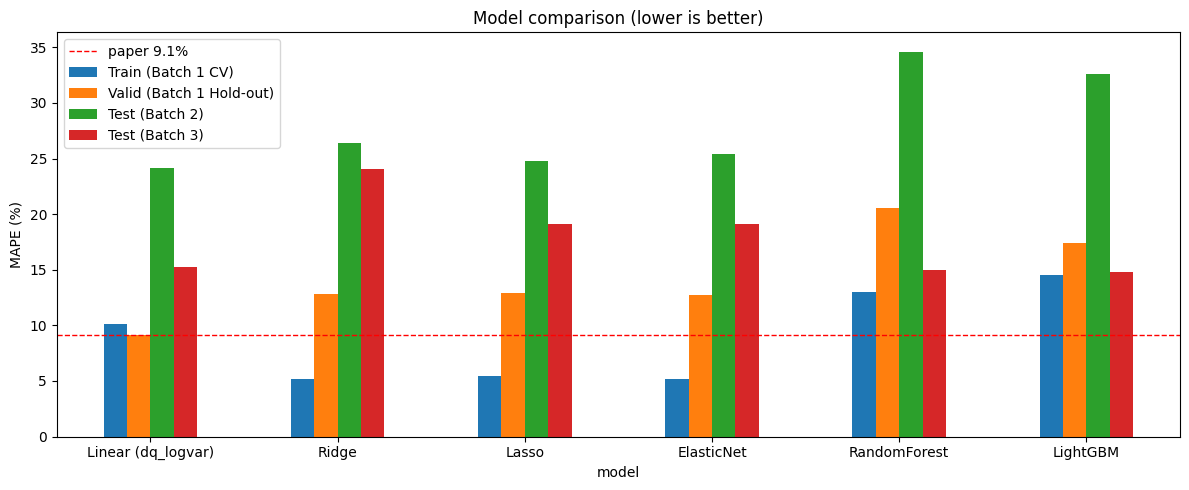

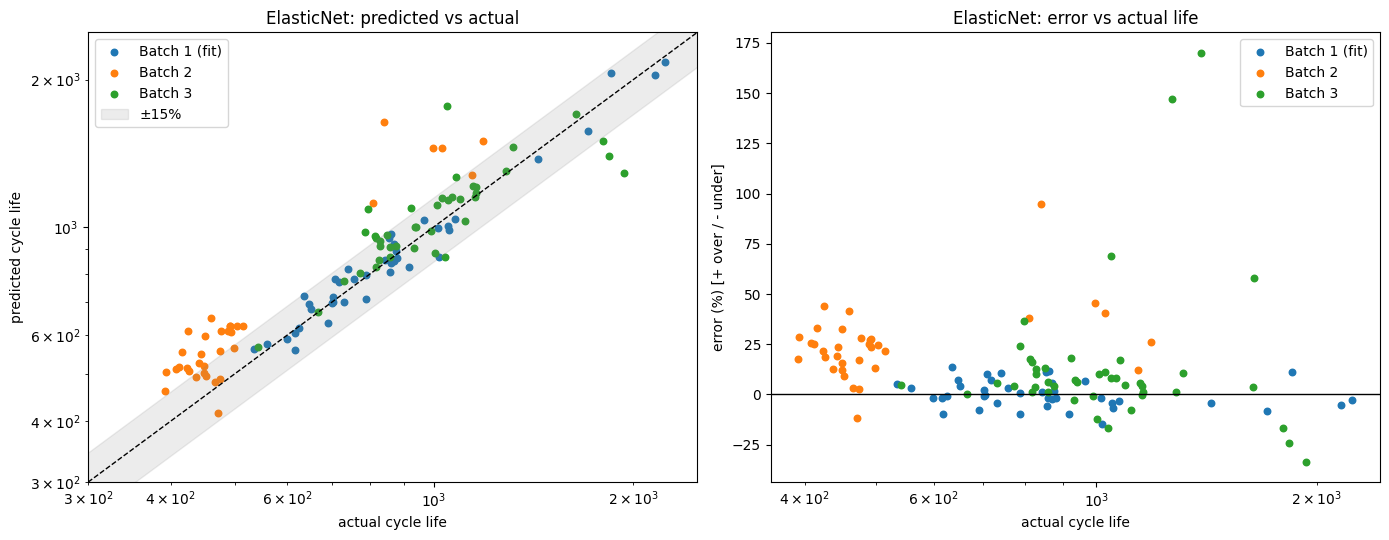

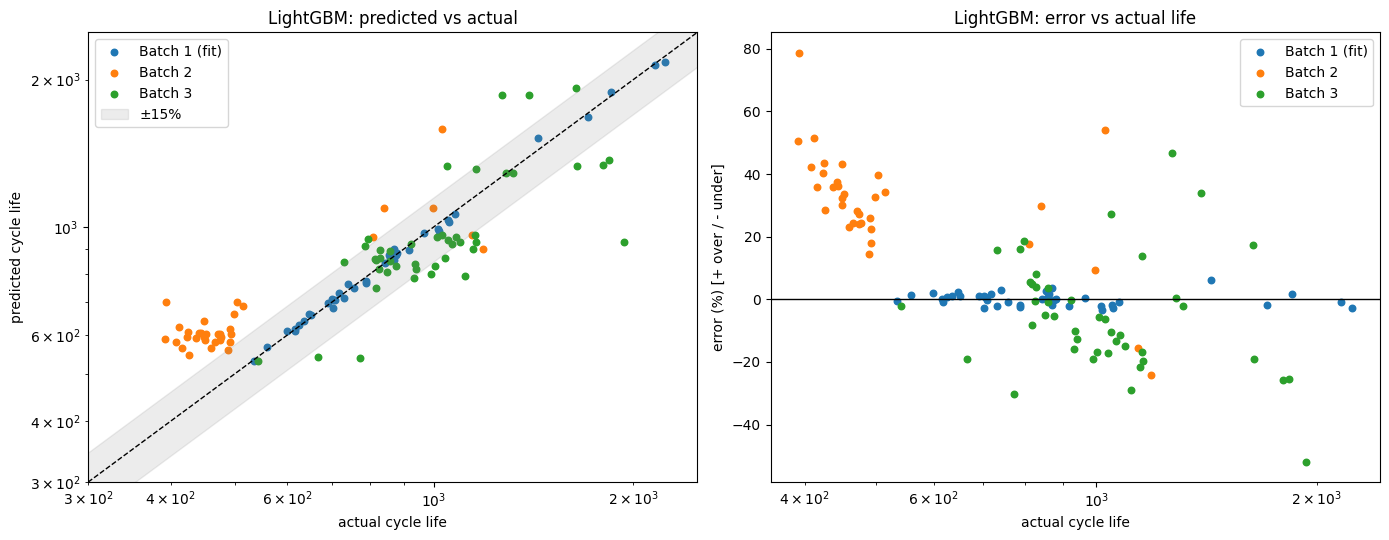

,구분,MAPE (%),비고
0,Train (Batch 1 CV),5.22,프로토콜 그룹 GroupKFold(5) 평균
1,Valid (Batch 1 Hold-out),12.71,프로토콜 단위 20% 분리
2,Test (Batch 2),25.41,Batch 1 전체 재학습 후 평가
3,Gap (Train-Valid),7.49,(+) : 과적합 의심
4,Gap (Valid-Test),12.70,(+) : 배치간 일반화 저하 의심
5,Gap (Target-Test),16.31,Target : 원논문 9.1% / (+) : 논문 대비 미달
6,Test (Batch 3),19.09,
7,Gap (Batch2-Batch3),-6.32,Test 성능 간 비교
8,"Gap (Target-Test, Batch 3)",9.99,"Batch 3 기준, 원논문 성능 비교"


,model,features,best_params,Train (Batch 1 CV),Train fit (참고),Valid (Batch 1 Hold-out),Test (Batch 2),Test (Batch 3),Gap (Train-Valid),Gap (Valid-Test),Gap (Target-Test),Gap (Batch2-Batch3),"Gap (Target-Test, Batch 3)"
0,Linear (dq_logvar),dq_logvar,{},10.17,8.88,9.15,24.18,15.26,-1.02,15.03,15.08,-8.92,6.16
1,Ridge,"dq_logvar, dq_logmin, dq_mean, dq_kurt, qd_2, ...","{""ridge__alpha"": 0.31622776601683794}",5.15,4.42,12.81,26.40,24.04,7.66,13.59,17.30,-2.36,14.94
2,Lasso,"dq_logvar, dq_logmin, dq_mean, dq_kurt, qd_2, ...","{""lasso__alpha"": 0.00031622776601683794}",5.46,4.43,12.94,24.77,19.14,7.48,11.83,15.67,-5.63,10.04
3,ElasticNet,"dq_logvar, dq_logmin, dq_mean, dq_kurt, qd_2, ...","{""elasticnet__alpha"": 0.0031622776601683794, ""...",5.22,4.43,12.71,25.41,19.09,7.49,12.70,16.31,-6.32,9.99
4,RandomForest,"dq_logvar, dq_logmin, dq_mean, dq_kurt, qd_2, ...","{""max_depth"": 3}",12.96,5.66,20.60,34.62,15.02,7.64,14.02,25.52,-19.60,5.92
5,LightGBM,"dq_logvar, dq_logmin, dq_mean, dq_kurt, qd_2, ...","{""max_depth"": 2}",14.53,1.43,17.41,32.59,14.82,2.88,15.18,23.49,-17.76,5.72


,split,cell,policy,cycle_life,pred_cycle_life,error(%),dq_logvar,target_out_of_b1_range,dq_logvar_out_of_b1_range
110,Batch 3,b3c37,4.8C(80%)-4.8C-newstructure,1390.0,3754.445619,170.104001,-5.098856,False,True
77,Batch 3,b3c2,5.6C(19%)-4.6C-newstructure,1267.0,3130.164042,147.053200,-4.779381,False,False
72,Batch 2,b2c44,5.2C(58%)-4C-newstructure,841.0,1638.263057,94.799412,-4.364523,False,False
116,Batch 3,b3c43,5C(67%)-4C-newstructure,1046.0,1769.553508,69.173376,-4.316748,False,False
115,Batch 3,b3c42,4.8C(80%)-4.8C-newstructure,1642.0,2591.393439,57.819332,-4.346195,False,False
73,Batch 2,b2c45,5.6C(26%)-4.5C-newstructure,997.0,1451.179037,45.554567,-4.175215,False,False
65,Batch 2,b2c31,5.6C(26%)-4.5C,425.0,611.148593,43.799669,-3.352359,True,False
51,Batch 2,b2c13,4.65C(69%)-6C,460.0,650.708777,41.458430,-3.344448,True,True
71,Batch 2,b2c43,4.8C(80%)-4.8C-newstructure,1029.0,1446.376333,40.561354,-4.271782,False,False
113,Batch 3,b3c40,5.6C(19%)-4.6C-newstructure,796.0,1086.640844,36.512669,-4.295108,False,False


count   mean
split   target_out_of_b1_range              
Batch 2 False                       6  42.87
        True                       28  21.67
Batch 3 False                      44  19.09

,mean,median
split,,
Batch 2,24.71,24.20
Batch 3,13.87,5.84


,feature,std_coef
0,dq_logvar,-0.1495
5,qd_max_minus_2,-0.0222
4,qd_2,0.0218
3,dq_kurt,0.0195
1,dq_logmin,-0.0024
2,dq_mean,0.0000


,n_holdout,Train (Batch 1 CV),Valid (Batch 1 Hold-out),Test (Batch 2),Test (Batch 3)
mean,9.35,7.44,8.86,33.38,17.07
std,0.99,1.39,3.23,5.02,2.51
min,8.00,4.63,4.18,25.41,13.58
max,11.00,9.12,13.80,39.66,20.66


In [9]:
out = run_all(feat, out_dir='/kaggle/working/results')
display(out['performance'])
display(out['comparison'].round(2))
display(out['errors']['top_errors'])
display(out['errors']['by_range'])
display(out['errors']['bias'])
display(out['coefficients'])
display(out['stability'])

In [2]:
import os
name = 'Linear (dq_logvar)'
out_dir = '/kaggle/working/results'
os.makedirs(f'{out_dir}/figures', exist_ok=True)

b1, train, holdout = split_batch1(feat)
tests = {'Batch 2': feat[feat.batch == 'b2'].reset_index(drop=True),
         'Batch 3': feat[feat.batch == 'b3'].reset_index(drop=True)}
est, grid, cols = get_models()[name]
res, final, preds = evaluate_model(name, est, grid, cols, b1, train, holdout, tests)

perf = performance_table(add_gaps(pd.DataFrame([res])).iloc[0])
perf.to_csv(f'{out_dir}/model_performance.csv', index=False, encoding='utf-8-sig')
display(perf)

pred_df = build_predictions(final, cols, b1, tests, preds)
pred_df.round(4).to_csv(f'{out_dir}/predictions.csv', index=False, encoding='utf-8-sig')
errors = error_analysis(pred_df)
display(errors['top_errors']); display(errors['by_range']); display(errors['bias'])
plot_pred_vs_actual(pred_df, f'{out_dir}/figures/pred_vs_actual_linear.png', 'Linear (dq_logvar)')

stab_raw, stab = holdout_stability(feat, model_name=name)
stab_raw.to_csv(f'{out_dir}/holdout_stability.csv', index=False)
display(stab)

OSError: [Errno 30] Read-only file system: '/kaggle'

In [ ]:
b12 = feat[feat.batch.isin(['b1', 'b2'])].reset_index(drop=True)
tr, te = b12.iloc[0::2], b12.iloc[1::2]
b3 = feat[feat.batch == 'b3']
print(f'train {len(tr)}셀 / test {len(te)}셀 / Batch 3 {len(b3)}셀')

for name in ['Linear (dq_logvar)', 'ElasticNet']:
    est, grid, cols = get_models()[name]
    gs = GridSearchCV(est, grid, scoring=MAPE_SCORER, cv=GroupKFold(5))
    gs.fit(tr[cols], tr['log_cl'], groups=tr['policy'])
    print(f'{name:20s} | 논문식 Test {mape_log(te["log_cl"], gs.predict(te[cols])):.2f}%'
          f' | Batch 3 {mape_log(b3["log_cl"], gs.predict(b3[cols])):.2f}%')